# House Price Prediction Using Multiple Linear Regression

## Assignment 2 – Group 3

## Introduction

House prices are influenced by several factors, including property size, location, condition, and the number of bedrooms and bathrooms. Understanding these factors can help real-estate companies make better pricing decisions.

In this project, we analyze the King County House Sales dataset, which contains 21,613 residential property sales and 21 original columns. We use multiple linear regression to study how different property characteristics relate to selling prices and develop a model to estimate house prices.

## Business Problem and Objectives

Setting the right selling price is important for real-estate companies. Overpricing a property may make it harder to sell, while underpricing could result in lost revenue.

Our goal is to develop a data-driven model that helps real-estate agents estimate house prices more consistently.

The main objectives of this project are:

1. Explore and prepare the housing dataset for analysis.
2. Identify property characteristics associated with selling prices.
3. Build a multiple linear regression model to predict house prices.
4. Evaluate the model using training and validation data.
5. Predict the selling price of a new house and assess whether the estimate is reasonable.

The results can help real-estate agents make more informed pricing recommendations while considering the limitations of the model.

In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

os.makedirs('part3_figures', exist_ok=True)

# Data Exploration, Cleaning and Feature Selection

In [7]:
df = pd.read_csv("kc_house_data.csv")

In [8]:
##inspecting the shape of data
df.shape

(21613, 21)

In [9]:
##inspecting the columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long           21

In [10]:
##checking for missing values
df.isnull().sum()

id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

In [11]:
##checking for duplicates and any repeated house IDs
print('Fully duplicated rows:', df.duplicated().sum())
print('Repeated house IDs   :', df['id'].duplicated().sum())

Fully duplicated rows: 0
Repeated house IDs   : 177


In [12]:
df.describe().T #statistical summary

,count,mean,std,min,25%,50%,75%,max
id,21613.0,4.580302e+09,2.876566e+09,1.000102e+06,2.123049e+09,3.904930e+09,7.308900e+09,9.900000e+09
price,21613.0,5.400881e+05,3.671272e+05,7.500000e+04,3.219500e+05,4.500000e+05,6.450000e+05,7.700000e+06
bedrooms,21613.0,3.370842e+00,9.300618e-01,0.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,3.300000e+01
bathrooms,21613.0,2.114757e+00,7.701632e-01,0.000000e+00,1.750000e+00,2.250000e+00,2.500000e+00,8.000000e+00
sqft_living,21613.0,2.079900e+03,9.184409e+02,2.900000e+02,1.427000e+03,1.910000e+03,2.550000e+03,1.354000e+04
sqft_lot,21613.0,1.510697e+04,4.142051e+04,5.200000e+02,5.040000e+03,7.618000e+03,1.068800e+04,1.651359e+06
floors,21613.0,1.494309e+00,5.399889e-01,1.000000e+00,1.000000e+00,1.500000e+00,2.000000e+00,3.500000e+00
waterfront,21613.0,7.541757e-03,8.651720e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
view,21613.0,2.343034e-01,7.663176e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00
condition,21613.0,3.409430e+00,6.507430e-01,1.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00


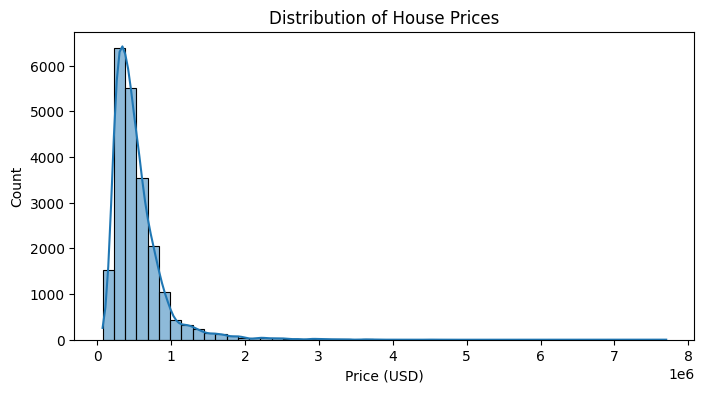

In [13]:
#Price Distribution
plt.figure(figsize=(8, 4))
sns.histplot(df['price'], bins=50, kde=True)
plt.title('Distribution of House Prices')
plt.xlabel('Price (USD)')
plt.show()

In [14]:
print("Skewness:", df['price'].skew())
print("Mean:", df['price'].mean())
print("Median:", df['price'].median()) 

Skewness: 4.024069144684714
Mean: 540088.1417665294
Median: 450000.0


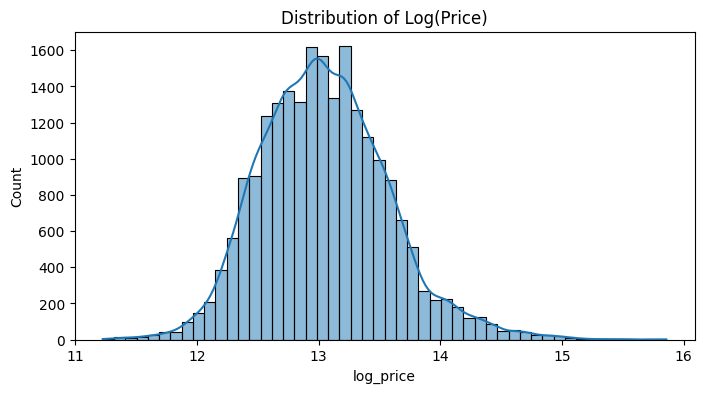

Skewness after log: 0.4280724755759251


In [15]:
df['log_price']= np.log(df['price'])

plt.figure(figsize=(8,4))
sns.histplot(df['log_price'], bins=50, kde=True)
plt.title('Distribution of Log(Price)')
plt.show()

print("Skewness after log:", df['log_price'].skew())

Price is strongly right-skewed (skewness = 4.02; mean = \$540,000 vs median = \$450,000), driven by a small number of high-value properties of up to \$7.7M. A log transformation reduces the skewness to 0.43. Log(price) is noted as an option, but the assignment requires `price` as the outcome, so `price` is used as the target in the regression.

In [16]:
#Checking for outliers
df[df['bedrooms'] >= 10][['bedrooms', 'bathrooms', 'sqft_living', 'price']]

,bedrooms,bathrooms,sqft_living,price
8757,11,3.00,3000,520000.0
13314,10,5.25,4590,1148000.0
15161,10,2.00,3610,650000.0
15870,33,1.75,1620,640000.0
19254,10,3.00,2920,660000.0


In [17]:
#checking for houses with 0 bedrooms or 0 bathrooms
df[(df['bedrooms'] == 0)| (df['bathrooms'] == 0)] [['bedrooms', 'bathrooms', 'sqft_living', 'price']]

,bedrooms,bathrooms,sqft_living,price
875,0,0.00,3064,1095000.0
1149,1,0.00,670,75000.0
3119,0,0.00,1470,380000.0
3467,0,1.50,1430,288000.0
4868,0,1.00,390,228000.0
5832,1,0.00,600,280000.0
6994,0,0.00,4810,1295650.0
8477,0,2.50,2290,339950.0
8484,0,2.50,1810,240000.0
9773,0,0.00,2460,355000.0


In [18]:
#Removing the 33-bedroom record and houses with 0 bedrooms or 0 bathrooms, as those are not realistic
rows_before = len(df)
df = df[df['bedrooms'] !=33]
df = df[(df['bedrooms'] > 0) & (df['bathrooms'] > 0)]
print("Rows removed:", rows_before - len(df))
print("Rows remaining:", len(df))

Rows removed: 17
Rows remaining: 21596


Upper limit: 1129500.0
Houses above limit: 1145


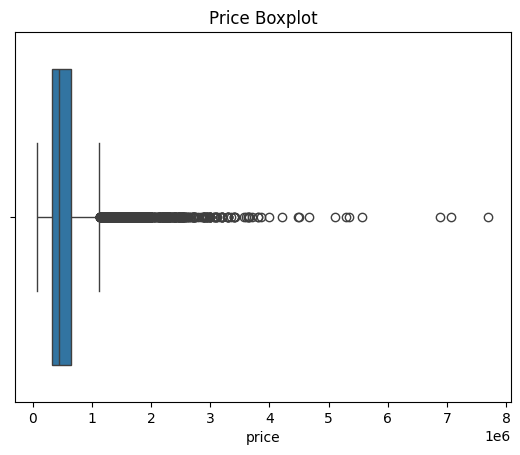

In [19]:
#Checking for price outliers

Q1= df['price'].quantile(0.25)
Q3= df['price'].quantile(0.75)
IQR= Q3 - Q1
upper = Q3 + 1.5 * IQR

print("Upper limit:", upper)
print("Houses above limit:", (df['price'] > upper).sum())

sns.boxplot(x=df['price'])
plt.title('Price Boxplot')
plt.show()

One record listed 33 bedrooms with only 1,620 sq ft and 1.75 bathrooms, which is a data entry error, so it was removed. 16 records reported 0 bedrooms or 0 bathrooms, including homes over 3,000 sq ft. These are not realistic for residential sales and were removed (0.08% of the data). About 1,145 high-price properties were flagged by the IQR rule but were retained, since they are genuine sales. This gives us a final dataset of 21,596 rows.

In [20]:
#Converting date from text to a real date format

df['date'] = pd.to_datetime(df['date'], format='%Y%m%dT%H%M%S')
df['date'].head()

0   2014-10-13
1   2014-12-09
2   2015-02-25
3   2014-12-09
4   2015-02-18
Name: date, dtype: datetime64[us]

In [21]:
#Creating a Sale_year and Sale_month column

df['sale_year'] = df['date'].dt.year
df['sale_month'] = df['date'].dt.month

df['sale_year'].value_counts()

sale_year
2014    14621
2015     6975
Name: count, dtype: int64

In [22]:
#Calculating the age of the houses

df['house_age'] = df['sale_year'] - df['yr_built']
df['house_age'].describe()

count    21596.000000
mean        43.322189
std         29.377523
min         -1.000000
25%         18.000000
50%         40.000000
75%         63.000000
max        115.000000
Name: house_age, dtype: float64

In [23]:
#It's impossible to have a house age that's negative, so we convert those to 0
df['house_age'] = df['house_age'].clip(lower=0)
df['house_age'].min()

np.int64(0)

In [24]:
#Creating a renovated column
df['renovated'] = (df['yr_renovated'] > 0).astype(int)
df['renovated'].value_counts()

renovated
0    20682
1      914
Name: count, dtype: int64

In [25]:
##Dropping columns that are not needed

df= df.drop(columns=['id', 'date', 'yr_renovated'])
df.columns

Index(['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
       'waterfront', 'view', 'condition', 'grade', 'sqft_above',
       'sqft_basement', 'yr_built', 'zipcode', 'lat', 'long', 'sqft_living15',
       'sqft_lot15', 'log_price', 'sale_year', 'sale_month', 'house_age',
       'renovated'],
      dtype='str')

The date field was converted from text to datetime and split into `sale_year` and `sale_month`. `house_age` was calculated as sale year minus year built; 12 homes were sold before construction was finished, which gave an age of -1, and these were converted to 0. A binary `renovated` flag replaced `yr_renovated` (914 renovated homes). `id`, `date` and `yr_renovated` were dropped since they are no longer needed.

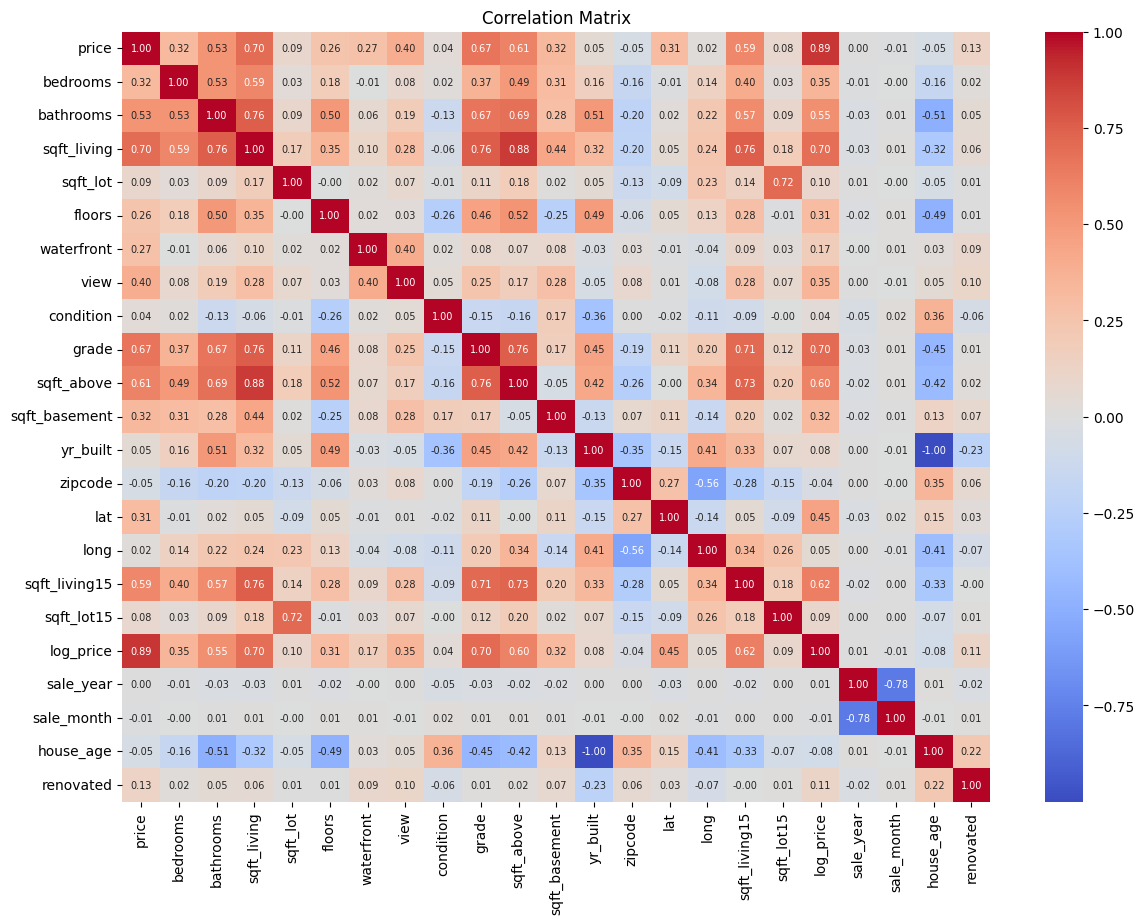

In [26]:

# Creating a correlation heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size': 7})
plt.title('Correlation Matrix')
plt.show()

In [27]:
#Rank features by correlation with log_price
df.corr(numeric_only=True)['log_price'].sort_values(ascending=False)

log_price        1.000000
price            0.891720
grade            0.703706
sqft_living      0.695170
sqft_living15    0.619351
sqft_above       0.601593
bathrooms        0.551251
lat              0.448884
bedrooms         0.350866
view             0.346594
sqft_basement    0.316879
floors           0.310668
waterfront       0.174690
renovated        0.114103
sqft_lot         0.100029
sqft_lot15       0.092282
yr_built         0.080625
long             0.050919
condition        0.038838
sale_year        0.005004
sale_month      -0.013075
zipcode         -0.038814
house_age       -0.080543
Name: log_price, dtype: float64

In [28]:
##checking where they overlap

print((df['sqft_living'] == df['sqft_above'] + df['sqft_basement']).all())
print(df[['sqft_living', 'sqft_above', 'sqft_living15']].corr())
print(df[['yr_built', 'house_age']].corr())

True
               sqft_living  sqft_above  sqft_living15
sqft_living       1.000000    0.876448       0.756400
sqft_above        0.876448    1.000000       0.731756
sqft_living15     0.756400    0.731756       1.000000
           yr_built  house_age
yr_built   1.000000  -0.999873
house_age -0.999873   1.000000


In [29]:
##Checking the zip codes
print("Unique zipcodes:", df['zipcode'].nunique())
df.groupby('zipcode')['price'].median().sort_values()

Unique zipcodes: 70


zipcode
98002     235000.0
98168     235000.0
98032     249000.0
98001     260000.0
98188     264000.0
           ...    
98005     765475.0
98112     915000.0
98040     993750.0
98004    1150000.0
98039    1892500.0
Name: price, Length: 70, dtype: float64

In [30]:
##Choosing the final columns
predictors = ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
              'waterfront', 'view', 'condition', 'grade',
              'house_age', 'renovated', 'lat', 'long',
              'sale_year', 'sale_month']

df_clean = df[predictors + ['price', 'log_price']]
df_clean.shape

(21596, 17)

In [31]:
##saving the clean dataset
df_clean.to_csv('kc_house_cleaned.csv', index=False)

# Summary: EDA, Cleaning and Feature Selection

**Output file:** `kc_house_cleaned.csv` (21,596 rows; 15 predictors + `price` + `log_price`)

### 1. Exploratory Data Analysis
- The original dataset contains 21,613 rows and 21 columns, with no missing values and no fully duplicated rows.
- 177 house IDs appear more than once. These are properties sold twice during the period, not errors, so they were retained.
- Price is strongly right-skewed (skewness = 4.02; mean = \$540k vs median = \$450k; max = \$7.7M).
- A log transformation reduces skewness to 0.43. `log_price` is kept in the file for reference, but `price` is used as the target, as the assignment requires.

### 2. Data Cleaning
- **Removed 1 record** with 33 bedrooms but only 1,620 sq ft and 1.75 bathrooms (a clear data entry error).
- **Removed 16 records** with 0 bedrooms or 0 bathrooms, which is implausible for residential homes.
- **Retained ~1,140 high-price outliers** (above ~\$1.13M by the IQR rule). These are genuine luxury sales.
- **Feature engineering:**
  - `sale_year` and `sale_month` extracted from `date`
  - `house_age` = sale year − year built (12 homes sold before completion had an age of −1 and were set to 0)
  - `renovated` = 1 if the home was ever renovated, otherwise 0 (914 homes; median price \$600k vs \$448k)
- **Dropped:** `id` (identifier only), `date` and `yr_renovated` (replaced by the new features).

### 3. Feature Selection
**Selected predictors (15):** bedrooms, bathrooms, sqft_living, sqft_lot, floors, waterfront, view, condition, grade, house_age, renovated, lat, long, sale_year, sale_month

- **Strongest predictors** (correlation with log price): grade (0.70), sqft_living (0.70), bathrooms (0.55), lat (0.45).
- **Kept for domain reasons despite weak correlation:** condition, sqft_lot, waterfront, renovated, sale_year and sale_month. These are standard drivers of house value or control for market timing.
- **Dropped for redundancy (multicollinearity):**
  - `sqft_above` and `sqft_basement`: together they add up exactly to `sqft_living`
  - `yr_built`: perfectly correlated with `house_age` (r = −1.00)
  - `sqft_living15` and `sqft_lot15`: overlap heavily with `sqft_living` (r = 0.76) and `sqft_lot` (r = 0.72)
- **Zipcode vs latitude/longitude:** `zipcode` is a categorical label (70 values), so its numeric correlation with price (−0.04) is misleading, and using it properly would require 69 dummy variables. `lat` and `long` capture location as continuous values, so they were kept and `zipcode` was dropped.

### Notes for Modelling
- Features with weak correlations can be tested for removal during modelling.
- `sqft_living15` was excluded as a judgment call. It is fairly strong (r = 0.62) and could be tested as an additional predictor.

---------------------------------------

# Building the Linear Regression Model and Displaying Coefficients

## Data Partition

In [32]:
# Data partition (predictors X, outcome y)

outcome = 'price'

X = pd.get_dummies(df_clean[predictors], drop_first=True)
y = df_clean[outcome]
print('X shape:', X.shape)
X.head()

X shape: (21596, 15)


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,house_age,renovated,lat,long,sale_year,sale_month
0,3,1.00,1180,5650,1.0,0,0,3,7,59,0,47.5112,-122.257,2014,10
1,3,2.25,2570,7242,2.0,0,0,3,7,63,1,47.7210,-122.319,2014,12
2,2,1.00,770,10000,1.0,0,0,3,6,82,0,47.7379,-122.233,2015,2
3,4,3.00,1960,5000,1.0,0,0,5,7,49,0,47.5208,-122.393,2014,12
4,3,2.00,1680,8080,1.0,0,0,3,8,28,0,47.6168,-122.045,2015,2


## Training/Validation split (60/40)

In [33]:
train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=0.4, random_state=1)
print('Training  :', train_X.shape)
print('Validation:', valid_X.shape)

Training  : (12957, 15)
Validation: (8639, 15)


## Fit the linear model on the training data

In [34]:
house_lm = LinearRegression()
house_lm.fit(train_X, train_y)

print('Intercept:', round(house_lm.intercept_, 2))
print(pd.DataFrame({'Predictor': X.columns, 'coefficient': house_lm.coef_}))

Intercept: -98687620.48
      Predictor    coefficient
0      bedrooms  -40465.457783
1     bathrooms   37453.727985
2   sqft_living     182.003153
3      sqft_lot      -0.079610
4        floors   13469.506557
5    waterfront  643708.141392
6          view   45347.633964
7     condition   27373.204262
8         grade  107512.142484
9     house_age    2541.942022
10    renovated   27116.862707
11          lat  549190.261496
12         long  -85921.726450
13    sale_year   30392.577914
14   sale_month     237.892334


In [35]:
# statsmodels OLS gives the same coefficients as LinearRegression, plus standard errors and p-values
ols = sm.OLS(train_y, sm.add_constant(train_X.astype(float))).fit()
print(f'Training R-squared: {ols.rsquared:.3f}   Adjusted R-squared: {ols.rsquared_adj:.3f}')

coef_table = pd.DataFrame({
    'Predictor': X.columns,
    'Coefficient': house_lm.coef_,
    'Std_Error': ols.bse[X.columns].values,
    'p_value': ols.pvalues[X.columns].values,
    # standardized coefficient = change in price (in SDs) for a 1-SD change in the predictor, so predictors can be compared
    'Std_Coefficient': house_lm.coef_ * train_X.std().values / train_y.std(),
})
coef_table['Rank'] = coef_table['Std_Coefficient'].abs().rank(ascending=False).astype(int)
coef_table = coef_table.sort_values('Rank').reset_index(drop=True)

pd.options.display.float_format = '{:,.4f}'.format
display(coef_table)
pd.options.display.float_format = '{:,.2f}'.format

Training R-squared: 0.691   Adjusted R-squared: 0.690


,Predictor,Coefficient,Std_Error,p_value,Std_Coefficient,Rank
0,sqft_living,182.0032,4.1129,0.0000,0.4546,1
1,grade,"107,512.1425","2,646.3202",0.0000,0.3448,2
2,lat,"549,190.2615","13,568.3237",0.0000,0.2080,3
3,house_age,"2,541.9420",94.8766,0.0000,0.2037,4
4,waterfront,"643,708.1414","22,848.1316",0.0000,0.1506,5
5,bedrooms,"-40,465.4578","2,600.1420",0.0000,-0.1002,6
6,view,"45,347.6340","2,732.7642",0.0000,0.0942,7
7,bathrooms,"37,453.7280","4,247.5256",0.0000,0.0787,8
8,condition,"27,373.2043","3,038.0910",0.0000,0.0486,9
9,sale_year,"30,392.5779","6,165.5708",0.0000,0.0388,10


## Visualization of Price vs Living Area

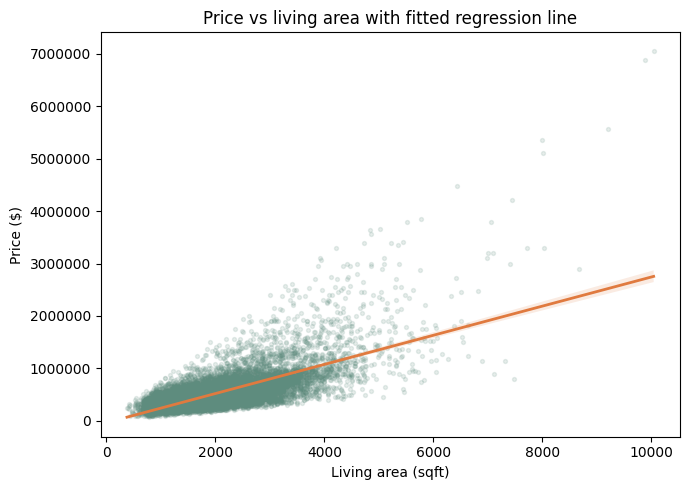

In [36]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(x=train_X['sqft_living'], y=train_y,
            scatter_kws={'alpha': 0.15, 's': 8, 'color': '#5E8C7E'},
            line_kws={'color': '#E07A3F', 'linewidth': 2}, ax=ax)
ax.set_xlabel('Living area (sqft)')
ax.set_ylabel('Price ($)')
ax.set_title('Price vs living area with fitted regression line')
ax.ticklabel_format(style='plain')
plt.tight_layout()
plt.show()

This chart shows living area on its own and it shows a clear positive, roughly linear relationship between living area and sale price, which means larger homes tend to sell for more. The points spread out more as homes get larger, so the model is less accurate for big, expensive homes. Additionally, a few luxury sales sit far above the line. Most homes are clustered at the lower end of living area and price, where the line fits best. In the full multiple regression, the effect of living area is about $182 per square foot, because other features such as grade and location also explain part of the price difference.

## Visualization - Chart of predictor importance

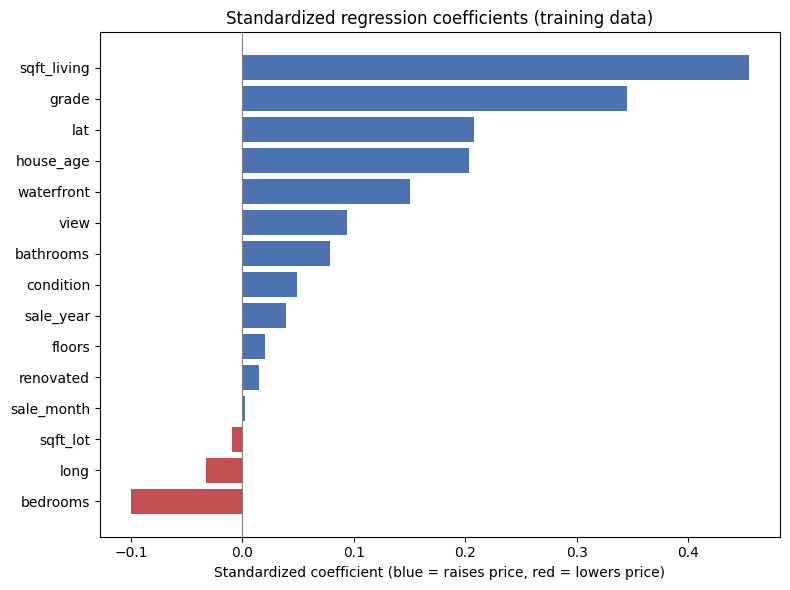

In [37]:
plot_df = coef_table.sort_values('Std_Coefficient')
colors = ['#C44E52' if v < 0 else '#4C72B0' for v in plot_df['Std_Coefficient']]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(plot_df['Predictor'], plot_df['Std_Coefficient'], color=colors)
ax.axvline(0, color='grey', linewidth=0.8)
ax.set_title('Standardized regression coefficients (training data)')
ax.set_xlabel('Standardized coefficient (blue = raises price, red = lowers price)')
plt.tight_layout()
plt.show()

## **Linear Regression Model and Coefficient Summary**

### **Dummy Variables**

Some predictors in our data are yes/no categories. Regression needs numbers, so these are coded as **dummy variables** (1 = yes, 0 = no). Our data already had them in this form, so `pd.get_dummies()` did not add any new columns.

We have two dummy variables:

- **`waterfront`** (1 = on the water, 0 = not). The coefficient is about **$644,000**. This means that if two houses are the same in every other way, the one on the waterfront sells for about $644,000 more. This is the biggest effect in our model. However, only about 1% of homes are waterfront, so the estimate is based on a small group.
- **`renovated`** (1 = renovated, 0 = never renovated). The coefficient is about **$27,000**. A renovated house sells for about $27,000 more than a similar house that was never renovated. This effect is real (p = 0.004) but small compared to size or grade.

We did **not** make dummies for `grade`, `view` and `condition`. These are ratings where a higher number means better, so we kept them as numbers. We also did not use `zipcode`, because it would need 69 dummy columns. We used `lat` and `long` for location instead.

### **Model and coefficient interpretation**
The cleaned data (21,596 sales) was split at random into a training set (60%, 12,957 sales) and a validation set (40%, 8,639 sales) with `random_state=1`. The multiple linear regression was estimated on the training set only, with `price` as the outcome. It explains about **69% of the variation in sale price** (R² = 0.691).

**Multicollinearity:** adding `sqft_above` and `sqft_basement` back gives a VIF of about 10¹⁵, because together they add up exactly to `sqft_living`. This confirms they were rightly excluded. In the final model every VIF is below 4.5, so the coefficients are stable enough to interpret.

**Most important predictors** (ranked by standardized coefficient; each effect holds all other predictors constant; all p < 0.001):
1. **Living area (`sqft_living`):** each extra square foot adds about **$182**, so 100 sqft adds about **$18,200**. Size is the strongest driver of price.
2. **Construction grade (`grade`):** each step up the 1–13 scale adds about **$107,500**. Build quality matters almost as much as size.
3. **Latitude (`lat`):** moving 0.01° north (about 1.1 km) adds about **$5,500**, reflecting the price gap between the expensive north/central county and the cheaper south.
4. **House age (`house_age`):** each extra 10 years adds about **$25,400**. Once grade, condition and location are controlled for, older homes tend to be character homes in established, desirable neighbourhoods.
5. **Waterfront (`waterfront`):** a waterfront home sells for about **$644,000 more** than an otherwise identical home, the largest dollar premium in the model. Only about 1% of homes are waterfront, so it ranks fifth.

Other effects: each extra **view** point adds about **$45,000**. An extra **bedroom** at the same living area lowers price by about **$40,500**, because the same space is split into smaller rooms. `sqft_lot` (p = 0.06) and `sale_month` (p = 0.80) are not statistically significant. As a linear number, month does not capture seasonality.

---------------------------------------

# Evaluation and Diagnostics

This part evaluates the multiple linear regression built in the previous section (`house_lm`, outcome = `price`, 15 predictors, 60/40 split with `random_state=1`), using `train_X`, `valid_X`, `train_y` and `valid_y` from the earlier parts.

Error convention: **error = actual - predicted**. A positive error means the model under-predicted the sale price.

## Predictions and error metrics

In [38]:
train_pred = house_lm.predict(train_X)
valid_pred = house_lm.predict(valid_X)

def regression_metrics(actual, predicted):
    e = actual - predicted
    return {
        'ME': e.mean(),
        'MAE': e.abs().mean(),
        'RMSE': np.sqrt((e ** 2).mean()),
        'MPE (%)': 100 * (e / actual).mean(),
        'MAPE (%)': 100 * (e / actual).abs().mean(),
        'R2': 1 - (e ** 2).sum() / ((actual - actual.mean()) ** 2).sum(),
    }

metrics = pd.DataFrame({'Training': regression_metrics(train_y, train_pred),
                        'Validation': regression_metrics(valid_y, valid_pred)}).T

# Why MAPE is reasonable here: prices are positive and nowhere near zero
print('Lowest sale price in the data: $%s' % format(int(df_clean['price'].min()), ','))
print('Mean sale price (all cleaned data): $%s' % format(int(df_clean['price'].mean()), ','))

pd.options.display.float_format = '{:,.3f}'.format
display(metrics)
metrics.to_csv('part3_metrics.csv')

Lowest sale price in the data: $78,000
Mean sale price (all cleaned data): $540,198


,ME,MAE,RMSE,MPE (%),MAPE (%),R2
Training,0.000,"126,499.254","203,882.822",-4.002,25.500,0.691
Validation,"4,113.548","125,356.542","200,872.456",-3.333,25.397,0.702


In [39]:
# Share of homes predicted within 10% / 20% of the true price, and median errors
for name, a, p in [('Training', train_y, train_pred), ('Validation', valid_y, valid_pred)]:
    e = a - p
    ape = 100 * (e / a).abs()
    print(f'{name:10s}  median |error| = ${e.abs().median():,.0f}   median APE = {ape.median():.1f}%   '
          f'within 10% = {(ape <= 10).mean():.1%}   within 20% = {(ape <= 20).mean():.1%}')

Training    median |error| = $88,430   median APE = 19.5%   within 10% = 27.6%   within 20% = 50.9%
Validation  median |error| = $86,689   median APE = 19.2%   within 10% = 28.2%   within 20% = 51.8%


In [40]:
# Training vs validation: how far apart are the errors?
cols = ['MAE', 'RMSE', 'MAPE (%)', 'R2']
gap = pd.DataFrame({'Training': metrics.loc['Training', cols],
                    'Validation': metrics.loc['Validation', cols]})
gap['Validation vs Training (%)'] = 100 * (gap['Validation'] / gap['Training'] - 1)
display(gap)

,Training,Validation,Validation vs Training (%)
MAE,"126,499.254","125,356.542",-0.903
RMSE,"203,882.822","200,872.456",-1.477
MAPE (%),25.500,25.397,-0.401
R2,0.691,0.702,1.655


## Diagnostic plots

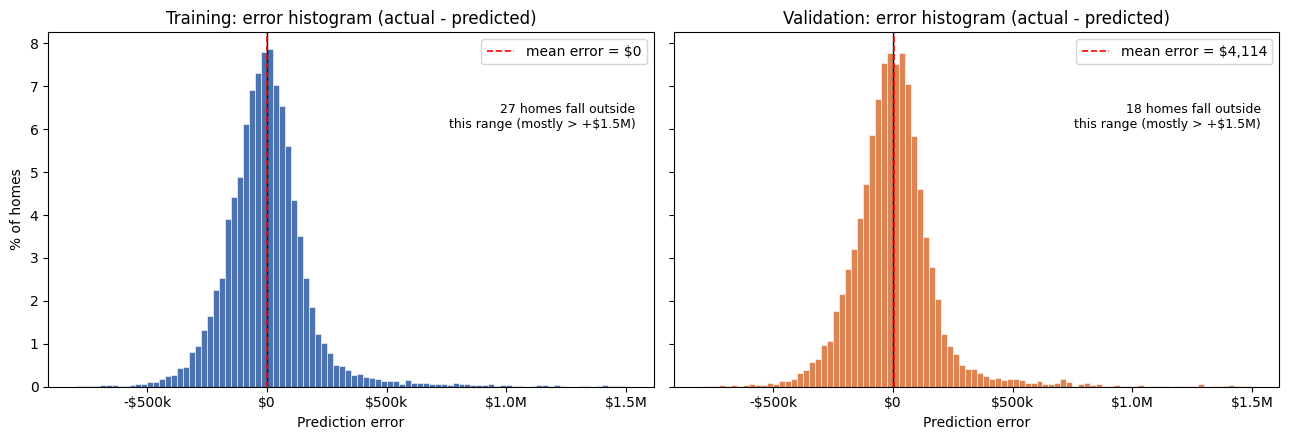

Skewness of errors  - training: 3.66  validation: 3.27
Excess kurtosis     - training: 45.8  validation: 40.3


In [41]:
def money(v, _=None):
    if v == 0:
        return '$0'
    s = '-' if v < 0 else ''
    v = abs(v)
    return f'{s}${v/1e6:,.1f}M' if v >= 1e6 else f'{s}${v/1e3:,.0f}k'

k_fmt = FuncFormatter(money)
blue, orange = '#4C72B0', '#DD8452'

train_err = train_y - train_pred
valid_err = valid_y - valid_pred
sets = [('Training', train_y, train_pred, train_err, blue),
        ('Validation', valid_y, valid_pred, valid_err, orange)]

# ---- Plot 1: histograms of prediction errors ----
lo, hi = -800_000, 1_500_000
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True, sharey=True)
for ax, (name, a, p, err, c) in zip(axes, sets):
    inside = err[(err >= lo) & (err <= hi)]
    ax.hist(inside, bins=np.arange(lo, hi + 25_000, 25_000),
            weights=np.full(len(inside), 100 / len(err)),
            color=c, edgecolor='white', linewidth=0.4)
    ax.axvline(0, color='black', lw=1)
    ax.axvline(err.mean(), color='red', ls='--', lw=1.2, label=f'mean error = ${err.mean():,.0f}')
    ax.text(0.97, 0.80, f'{len(err) - len(inside):,} homes fall outside\nthis range (mostly > +$1.5M)',
            transform=ax.transAxes, ha='right', va='top', fontsize=9)
    ax.set_title(f'{name}: error histogram (actual - predicted)')
    ax.set_xlabel('Prediction error')
    ax.xaxis.set_major_formatter(k_fmt)
    ax.legend(loc='upper right')
axes[0].set_ylabel('% of homes')
plt.tight_layout()
plt.savefig('part3_figures/1_error_histograms.png', dpi=150, bbox_inches='tight')
plt.show()

print('Skewness of errors  - training: %.2f  validation: %.2f' % (train_err.skew(), valid_err.skew()))
print('Excess kurtosis     - training: %.1f  validation: %.1f' % (train_err.kurt(), valid_err.kurt()))

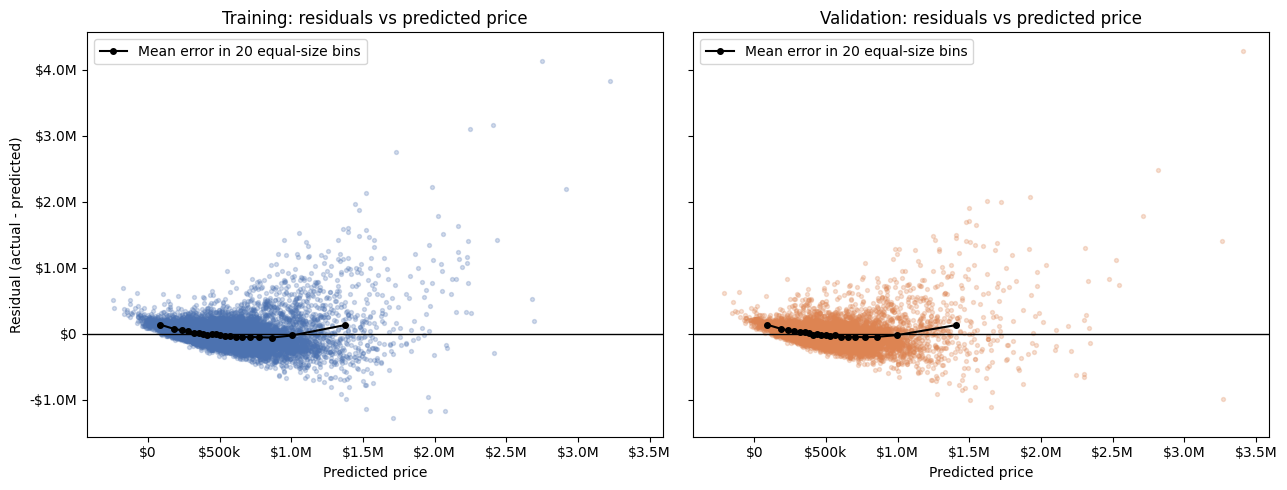

In [42]:
# ---- Plot 2: residuals vs predicted values ----
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, (name, a, p, err, c) in zip(axes, sets):
    ax.scatter(p, err, s=8, alpha=0.25, color=c)
    ax.axhline(0, color='black', lw=1)
    d = pd.DataFrame({'pred': p, 'err': err.values})
    d['bin'] = pd.qcut(d['pred'], 20)
    tr = d.groupby('bin', observed=True)[['pred', 'err']].mean()
    ax.plot(tr['pred'], tr['err'], color='black', marker='o', ms=4, lw=1.5,
            label='Mean error in 20 equal-size bins')
    ax.set_title(f'{name}: residuals vs predicted price')
    ax.set_xlabel('Predicted price')
    ax.xaxis.set_major_formatter(k_fmt)
    ax.yaxis.set_major_formatter(k_fmt)
    ax.legend(loc='upper left')
axes[0].set_ylabel('Residual (actual - predicted)')
plt.tight_layout()
plt.savefig('part3_figures/2_residuals_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()

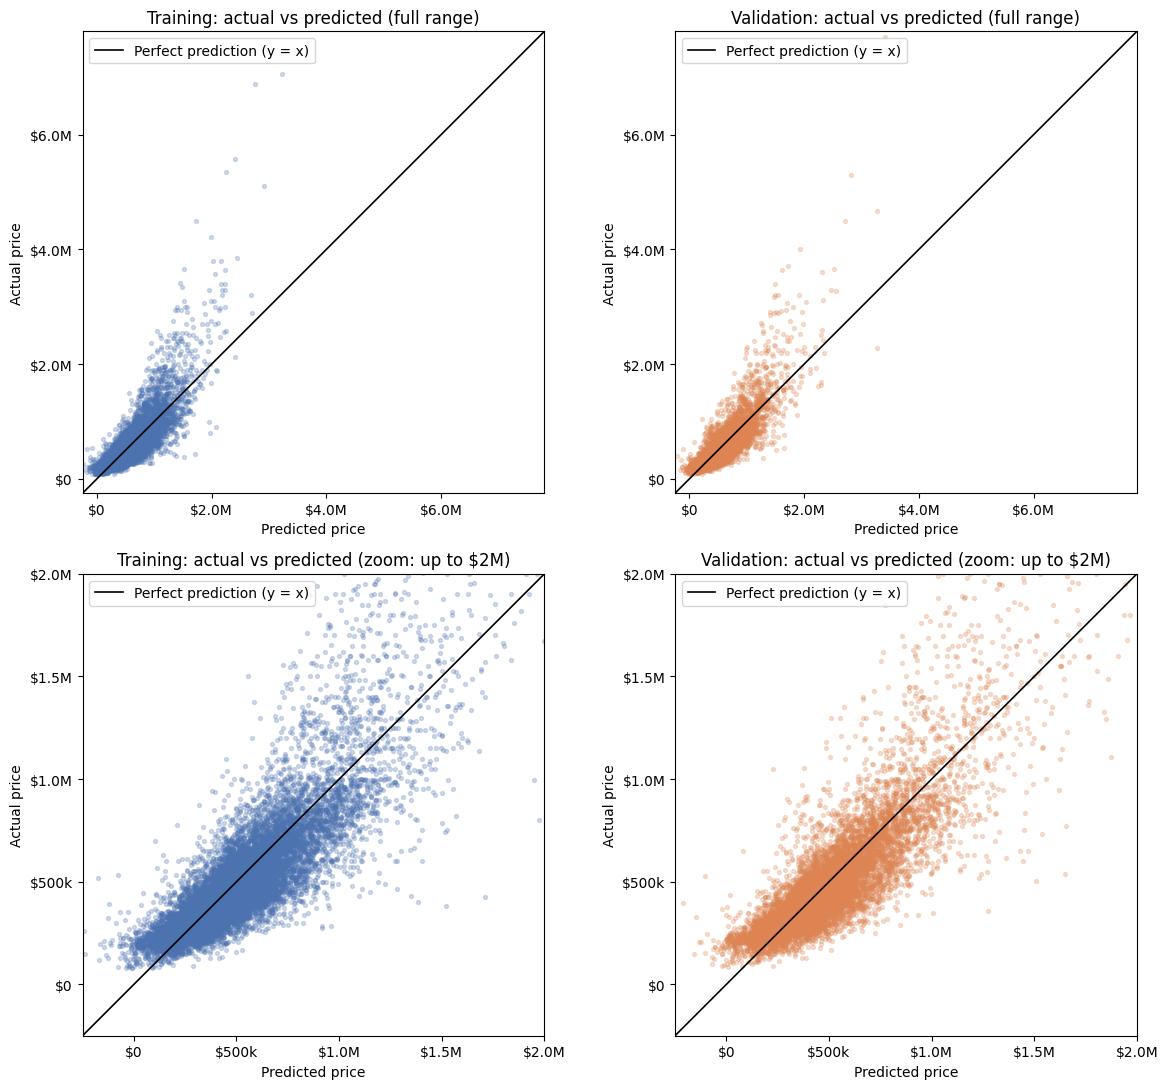

In [43]:
# ---- Plot 3: actual vs predicted (top row: full range, bottom row: zoom) ----
views = [('full range', (-250_000, 7_800_000)), ('zoom: up to $2M', (-250_000, 2_000_000))]
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
for r, (vname, (vlo, vhi)) in enumerate(views):
    for ax, (name, a, p, err, c) in zip(axes[r], sets):
        ax.scatter(p, a, s=8, alpha=0.25, color=c)
        ax.plot([vlo, vhi], [vlo, vhi], color='black', lw=1.2, label='Perfect prediction (y = x)')
        ax.set_xlim(vlo, vhi)
        ax.set_ylim(vlo, vhi)
        ax.set_aspect('equal', adjustable='box')
        ax.set_title(f'{name}: actual vs predicted ({vname})')
        ax.set_xlabel('Predicted price')
        ax.set_ylabel('Actual price')
        ax.xaxis.set_major_locator(MaxNLocator(5))
        ax.yaxis.set_major_locator(MaxNLocator(5))
        ax.xaxis.set_major_formatter(k_fmt)
        ax.yaxis.set_major_formatter(k_fmt)
        ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('part3_figures/3_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()

## Numbers behind the patterns (error size, outliers)

In [44]:
# Error size by predicted-price quintile (same bins logic as the residual plot)
def by_predicted_quintile(actual, pred):
    e = actual - pred
    q = pd.qcut(pred, 5, labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4', 'Q5 (highest)'])
    g = lambda s: s.groupby(q, observed=True)
    return pd.DataFrame({'mean error': g(e).mean(),
                         'residual SD': g(e).std(),
                         'MAE': g(e.abs()).mean(),
                         'MAPE (%)': g(100 * (e / actual).abs()).mean()})

pd.options.display.float_format = '{:,.1f}'.format
for name, a, p, err, c in sets:
    print(f'--- {name}: error by predicted-price quintile')
    q_actual = pd.Series(p, index=a.index)
    display(by_predicted_quintile(a, q_actual))
    print('correlation between |error| and predicted price: %.2f' % np.corrcoef(err.abs(), p)[0, 1])

--- Training: error by predicted-price quintile


,mean error,residual SD,MAE,MAPE (%)
Q1 (lowest),"72,700.6","86,938.8","85,996.8",32.4
Q2,-521.6,"94,749.4","72,600.6",21.1
Q3,"-20,568.3","123,488.6","98,955.1",23.4
Q4,"-48,587.7","148,305.5","123,230.1",23.8
Q5 (highest),"-3,049.8","382,139.2","251,680.9",26.7


correlation between |error| and predicted price: 0.49
--- Validation: error by predicted-price quintile


,mean error,residual SD,MAE,MAPE (%)
Q1 (lowest),"74,048.8","90,849.7","87,508.3",32.4
Q2,"8,316.7","107,986.8","79,803.4",22.1
Q3,"-17,769.8","121,707.3","94,902.3",22.8
Q4,"-44,775.9","153,944.0","124,583.2",24.6
Q5 (highest),735.3,"368,166.5","239,967.9",25.2


correlation between |error| and predicted price: 0.48


In [45]:
# Outliers: how concentrated is the error?
upper_iqr = 1_129_500   # IQR upper limit used in the cleaning step
for name, a, p, err, c in sets:
    sd = err.std()
    sq = (err ** 2).sort_values(ascending=False)
    exp = a > upper_iqr
    print(f'--- {name}')
    print(f'  homes with |error| > 3 SD       : {(err.abs() > 3 * sd).sum()} ({(err.abs() > 3 * sd).mean():.2%})')
    print(f'  share of squared error from top 1% of homes: {sq.head(int(len(sq) * 0.01)).sum() / sq.sum():.1%}')
    print(f'  share of squared error from top 5% of homes: {sq.head(int(len(sq) * 0.05)).sum() / sq.sum():.1%}')
    print(f'  homes sold above ${upper_iqr:,}: n = {exp.sum()}, MAE = ${err[exp].abs().mean():,.0f}, mean error = ${err[exp].mean():,.0f}')
    print(f'  all other homes                 : MAE = ${err[~exp].abs().mean():,.0f}')
    print(f'  correlation (error, actual price): {np.corrcoef(err, a)[0, 1]:.2f}')
    print(f'  negative predicted prices       : {(p < 0).sum()} (lowest = ${p.min():,.0f})')

def worst_errors(actual, pred, Xs, n=5):
    out = Xs[['sqft_living', 'grade', 'bedrooms']].copy()
    out['actual'] = actual
    out['predicted'] = pred
    out['error'] = actual - pred
    return out.reindex(out['error'].abs().sort_values(ascending=False).index).head(n)

pd.options.display.float_format = '{:,.0f}'.format
print('\nFive largest errors - training')
display(worst_errors(train_y, pd.Series(train_pred, index=train_y.index), train_X))
print('Five largest errors - validation')
display(worst_errors(valid_y, pd.Series(valid_pred, index=valid_y.index), valid_X))

--- Training
  homes with |error| > 3 SD       : 205 (1.58%)
  share of squared error from top 1% of homes: 40.3%
  share of squared error from top 5% of homes: 62.9%
  homes sold above $1,129,500: n = 688, MAE = $460,270, mean error = $411,467
  all other homes                 : MAE = $107,783
  correlation (error, actual price): 0.56
  negative predicted prices       : 66 (lowest = $-242,206)
--- Validation
  homes with |error| > 3 SD       : 148 (1.71%)
  share of squared error from top 1% of homes: 38.3%
  share of squared error from top 5% of homes: 62.5%
  homes sold above $1,129,500: n = 457, MAE = $450,738, mean error = $387,331
  all other homes                 : MAE = $107,183
  correlation (error, actual price): 0.54
  negative predicted prices       : 33 (lowest = $-212,085)

Five largest errors - training


,sqft_living,grade,bedrooms,actual,predicted,error
9254,9890,13,6,"6,885,000","2,752,590","4,132,410"
3914,10040,11,5,"7,062,500","3,226,084","3,836,416"
4411,9200,13,5,"5,570,000","2,409,164","3,160,836"
1448,8000,12,5,"5,350,000","2,244,830","3,105,170"
8638,6430,12,4,"4,489,000","1,729,444","2,759,556"


Five largest errors - validation


,sqft_living,grade,bedrooms,actual,predicted,error
7252,12050,13,6,"7,700,000","3,409,560","4,290,440"
1315,7390,12,6,"5,300,000","2,813,700","2,486,300"
4149,7080,12,4,"4,000,000","1,922,709","2,077,291"
19148,5490,12,5,"3,635,000","1,620,747","2,014,253"
16302,5550,12,4,"3,710,000","1,719,895","1,990,105"


## Performance Evaluation

The linear regression was scored on the 12,957 training sales and the 8,639 validation sales (error = actual - predicted).

| Set | ME | MAE | RMSE | MPE | MAPE | R² |
|---|---|---|---|---|---|---|
| Training | \$0 | \$126,499 | \$203,883 | -4.00% | 25.50% | 0.691 |
| Validation | \$4,114 | \$125,357 | \$200,872 | -3.33% | 25.40% | 0.702 |

**How to read the metrics**

- **MAE.** On average a predicted price is about \$125,000 away from the real sale price, roughly 23% of the average price (about \$540,000). The median absolute error is lower (about \$87,000 on validation), so a typical home is predicted better than the average suggests.
- **RMSE.** RMSE (\$201,000 to \$204,000) is about 1.6 times the MAE. RMSE squares each error, so it is pulled up by a small number of very large misses on expensive homes. A gap this big between RMSE and MAE is a sign of a heavy-tailed error distribution.
- **ME.** The training ME is exactly 0 by construction, because OLS with an intercept forces the residuals to sum to zero. The validation ME is +\$4,114 (under 1% of the average price), so the model is essentially unbiased in dollar terms. The positive sign means actual prices were very slightly higher than predicted.
- **R².** The model explains about 69% (training) and 70% (validation) of the variation in price.
- **Hit rate.** On validation, 28% of homes are predicted within 10% of the real price and 52% within 20%.

**Decision on MAPE: we report it, as a secondary metric next to MAE.**

1. House prices are strictly positive and far from zero (the cheapest sale is \$78,000), so dividing by the actual price never blows up. This is the condition that makes MAPE safe to use.
2. Prices range from \$78,000 to \$7.7M, so a relative error is easier to interpret than a dollar error. A \$100,000 miss is serious on a \$300,000 home and minor on a \$3M home.
3. MAPE is scale-free and easy to explain to agents: "typical estimates are off by about 25%".

Limits to keep in mind: MAPE penalises over-prediction more than under-prediction (an under-prediction can never exceed 100%, an over-prediction can), and it is inflated by cheap homes (about 38% in the lowest price quintile versus about 19% in the highest). For that reason MAE stays the main comparison metric (as in the model comparison section) and MAPE is read alongside it.

**MPE versus ME.** MPE is negative (-3.3% to -4.0%) while the dollar ME is close to zero. In percentage terms the model slightly over-predicts typical homes (mean percentage error of about -8% to -12% for homes priced between roughly \$295,000 and \$520,000). In dollars this is cancelled by the large under-predictions on expensive homes (see Residual Analysis).

## Overfitting

| Metric | Training | Validation | Validation vs training |
|---|---|---|---|
| MAE | \$126,499 | \$125,357 | -0.9% |
| RMSE | \$203,883 | \$200,872 | -1.5% |
| MAPE | 25.50% | 25.40% | -0.4% |
| R² | 0.691 | 0.702 | +0.011 |

- **No overfitting.** Validation errors are as small as training errors, and slightly smaller. If the model had memorised the training data, validation errors would be clearly larger. The small advantage for validation is random variation from a single random split and is far too small to matter.
- **Why this is expected.** The model has only 15 predictors, all entering linearly, and about 13,000 training rows. That is a low-variance model, so it behaves the same on new data.
- **The real limitation is underfitting (bias).** Both sets show R² of about 0.70 and a MAPE of about 25%. The model is stable, but it cannot capture non-linear patterns, so its accuracy is limited on both sets.
- **Contrast with the Random Forest** (team comparison table): its MAE is \$31,524 on training and \$69,719 on validation, so the validation error is 2.2 times the training error. That is clear overfitting, yet its validation MAE is still about 44% lower than the linear regression's \$125,357. Overfitting alone therefore does not decide which model is better; what matters is the error on unseen data.
- **Caveat.** This conclusion rests on one 60/40 split. K-fold cross-validation would confirm that the small gap is not an accident of the split.

## Residual Analysis

Plots: `part3_figures/1_error_histograms.png`, `2_residuals_vs_predicted.png`, `3_actual_vs_predicted.png`. Training and validation show the same patterns, which supports the conclusion that the model is stable.

**1. Error histograms: centred near zero, but heavily right-skewed.** Most errors are within a few tens of thousands of dollars of zero, but there is a long right tail. Error skewness is about 3.3 (validation) and 3.7 (training), and excess kurtosis is about 40 to 46, far from a normal distribution. The right tail contains homes that sold for much more than predicted. Prediction intervals built on a normality assumption would therefore not be reliable.

**2. Residuals vs predicted: a funnel shape (non-constant variance).** The spread of the residuals grows with the predicted price. The residual standard deviation rises from about \$87,000 to \$91,000 in the lowest predicted-price quintile to about \$368,000 to \$382,000 in the highest, and the MAE rises from about \$86,000 to \$250,000. The correlation between the absolute error and the predicted price is about 0.48. This breaks the constant-variance assumption of linear regression. The coefficients stay unbiased, but their standard errors and p-values in the coefficient table are less reliable than they look.

The mean-error line is also not flat: it is positive at the low end (about +\$73,000 to +\$74,000), negative in the middle (about -\$18,000 to -\$49,000) and back near zero at the top. This systematic curve shows the price relationship is not purely linear. In addition, 66 training and 33 validation homes receive a *negative* predicted price (lowest about -\$242,000), because a linear model has nothing that keeps predictions positive.

**3. Actual vs predicted: large errors on expensive homes.** Between roughly \$200,000 and \$1M the points follow the 45-degree line, but they fan out as prices rise and fall mostly above the line, meaning the actual price is higher than predicted. Homes that sold above \$1.13M (the IQR upper limit used in cleaning; 457 homes in validation) have an MAE of about \$451,000 against about \$107,000 for all other homes, and a mean error of about +\$387,000. The model systematically under-predicts luxury homes, which pulls the fitted line down at the top end.

**4. Outliers.** About 1.6% to 1.7% of homes have an error beyond 3 standard deviations (205 in training, 148 in validation). The worst 1% of homes produce roughly 38% to 40% of the total squared error and the worst 5% about 63%. The largest misses are the most expensive sales: for example a \$7.7M home predicted at about \$3.4M in validation (error about \$4.3M), and \$6.9M and \$7.1M homes in training (errors of about \$4.1M and \$3.8M). These are genuine luxury sales that the team kept during cleaning, not data errors, so the large errors are a model weakness and not a data problem. They are also the reason RMSE is so much larger than MAE.

**5. Implications and suggested improvements** (suggestions, not tested here).

- Model `log(price)` instead of `price`, as already suggested in the EDA (skewness falls from 4.02 to 0.43). Errors then become proportional to the price, which should reduce the funnel shape and keep predictions positive.
- Add non-linear terms or interactions (for example `sqft_living` squared, or `grade` with `sqft_living`) and a stronger location effect.
- Use a model that captures these patterns directly, such as the Random Forest (validation MAE \$69,719).
- Report prediction error to clients as a range that widens with price, for example "about \$85,000 for a typical home but several hundred thousand dollars for homes above \$1M".

------------

# Comparison with Advanced or AI-Based Methods

In [46]:
# Train an advanced model (Random Forest) on the same training data

rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=1, n_jobs=-1)
rf.fit(train_X, train_y)
print('Random forest trained on', train_X.shape[0], 'sales')

Random forest trained on 12957 sales


In [47]:
# Compare predictive performance (training and validation)
def regression_metrics(actual, predicted):
    e = actual - predicted
    return {
        'ME':   e.mean(),
        'MAE':  e.abs().mean(),
        'RMSE': np.sqrt((e ** 2).mean()),
        'MPE':  100 * (e / actual).mean(),
        'MAPE': 100 * (e / actual).abs().mean(),
    }

rows = []
for name, model in [('Linear Regression', house_lm), ('Random Forest', rf)]:
    rows.append({'Model': name, 'Data': 'Training',   **regression_metrics(train_y, model.predict(train_X))})
    rows.append({'Model': name, 'Data': 'Validation', **regression_metrics(valid_y, model.predict(valid_X))})
compare = pd.DataFrame(rows)

pd.options.display.float_format = '{:,.2f}'.format
display(compare)
compare.to_csv('extra_model_comparison.csv', index=False)

,Model,Data,ME,MAE,RMSE,MPE,MAPE
0,Linear Regression,Training,0.00,"126,499.25","203,882.82",-4.00,25.50
1,Linear Regression,Validation,"4,113.55","125,356.54","200,872.46",-3.33,25.40
2,Random Forest,Training,279.93,"31,524.17","62,143.29",-1.59,5.90
3,Random Forest,Validation,"1,434.51","69,718.69","130,509.41",-3.08,12.92


We chose **MAE** to compare the two models because it measures how far, in dollars, a predicted price is from the actual sale price on average. This links directly to the business problem. Agents need to know how much a price estimate could be off when advising a client, and a statement like "the estimate is usually within about $70,000" is easy to explain. MAE also treats every dollar of error equally, so it is not distorted much by a few very expensive homes.


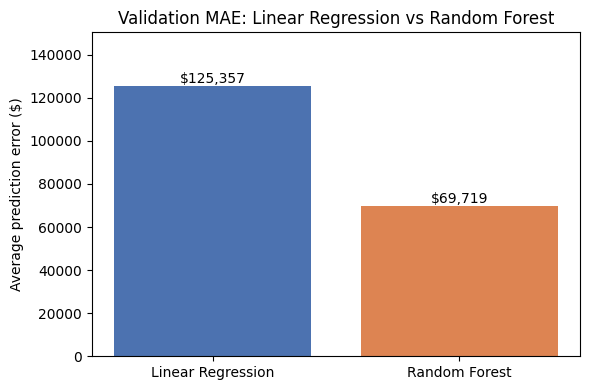

In [48]:
# Chart - validation MAE of both models
val = compare[compare['Data'] == 'Validation'].set_index('Model')
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(val.index, val['MAE'], color=['#4C72B0', '#DD8452'])
ax.bar_label(bars, labels=[f'${v:,.0f}' for v in val['MAE']])
ax.set_ylim(0, val['MAE'].max() * 1.2)
ax.set_ylabel('Average prediction error ($)')
ax.set_title('Validation MAE: Linear Regression vs Random Forest')
plt.tight_layout()
plt.show()

### **Comparison with an advanced method (Random Forest)**
A Random Forest, which combines many decision trees, was trained on the same training data and tested on the same validation data as the linear regression. The models are compared using **mean absolute error (MAE)**, the average dollar amount by which a predicted price differs from the actual sale price.

**Predictive performance:** the Random Forest is much more accurate. Its predictions are off by about **$69,700** on average, compared with **$125,400** for linear regression, which roughly halves the error. However, the Random Forest's training MAE ($31,500) is much lower than its validation MAE. This shows some overfitting: it fits the training data more closely than new data. Linear regression has almost the same MAE on training ($126,500) and validation ($125,400), so it is more stable.

**Strengths and weaknesses:**
- *Linear regression:* simple, fast and stable, with no overfitting. However, it assumes straight-line relationships, so it misses more complex patterns and makes large errors on expensive homes.
- *Random Forest:* captures non-linear patterns and interactions between features, which makes it much more accurate. However, it overfits more and is harder to explain.

**Interpretability:** linear regression gives a clear dollar value for each feature (e.g., about $18,200 per extra 100 sqft, about $644,000 for waterfront), which agents can easily explain to clients. The Random Forest only shows which features matter most (grade, living area and latitude), not how many dollars each one adds.

**Business usefulness:** the Random Forest is better for producing an accurate price estimate, while linear regression is better for explaining *why* a house is priced a certain way. Agents could use the Random Forest for the estimate and the linear regression coefficients to explain it to clients.

---------

# New-House Price Prediction and Final Integration

## Predicting the Price of a New House

In this section, we use the multiple linear regression model built earlier to estimate the selling price of a new residential property in King County, Washington.

In [49]:
# Check the predictors used in the regression model
print("Predictor variables:")
print(train_X.columns.tolist())

Predictor variables:
['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'house_age', 'renovated', 'lat', 'long', 'sale_year', 'sale_month']


In [50]:
# Creating a new house for price prediction

new_house = pd.DataFrame([{
    'bedrooms': 3,
    'bathrooms': 2,
    'sqft_living': 1800,
    'sqft_lot': 5000,
    'floors': 2,
    'waterfront': 0,
    'view': 0,
    'condition': 3,
    'grade': 7,
    'house_age': 20,
    'renovated': 0,
    'lat': 47.55,
    'long': -122.25,
    'sale_year': 2015,
    'sale_month': 5
}])

# Match the predictor columns used in the trained model
new_house = new_house[train_X.columns]

# Display the new house
display(new_house)

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,house_age,renovated,lat,long,sale_year,sale_month
0,3,2,1800,5000,2,0,0,3,7,20,0,47.55,-122.25,2015,5


In [51]:
# Predict the new house price using multiple linear regression

predicted_price = house_lm.predict(new_house)[0]

print(f"Predicted House Price: ${predicted_price:,.2f}")

Predicted House Price: $365,742.64


In [52]:
# Find houses with similar characteristics

similar_houses = df[
    (df['bedrooms'] == 3) &
    (df['bathrooms'].between(1.5, 2.5)) &
    (df['sqft_living'].between(1500, 2100)) &
    (df['grade'].between(6, 8))
].copy()

# Display comparison results
print("Number of similar houses:", len(similar_houses))

if len(similar_houses) > 0:
    print(f"Average selling price: ${similar_houses['price'].mean():,.2f}")
    print(f"Median selling price: ${similar_houses['price'].median():,.2f}")
    print(f"Minimum selling price: ${similar_houses['price'].min():,.2f}")
    print(f"Maximum selling price: ${similar_houses['price'].max():,.2f}")
else:
    print("No houses matched the selected criteria.")

Number of similar houses: 3244
Average selling price: $429,028.94
Median selling price: $412,500.00
Minimum selling price: $158,000.00
Maximum selling price: $1,500,000.00


## Interpretation of the Predicted House Price

Our multiple linear regression model predicted a selling price of $365,742.64 for a house with 3 bedrooms, 2 bathrooms, 1,800 square feet of living space, and a property grade of 7.

To check whether this prediction was reasonable, we compared it with 3,244 houses in the dataset that had similar characteristics.

The average selling price of these houses was $429,028.94, while the median was $412,500. Our predicted price was slightly lower than both values but remained within the observed selling price range of $158,000 to $1,500,000.

Based on this comparison, the predicted price appears reasonable. However, location and other property characteristics can also influence house prices, so the estimate should be treated as a starting point rather than an exact selling price.

In [53]:
# Verify that the new house values are within the dataset range
print("NEW HOUSE VALIDATION")
print("-" * 65)
for column in new_house.columns:
    if column in df.columns:
        minimum = df[column].min()
        maximum = df[column].max()
        value = new_house[column].iloc[0]
        status = "VALID" if minimum <= value <= maximum else "OUT OF RANGE"
        print(f"{column}: {value} | Range: {minimum} - {maximum} | {status}")
    else:
        print(f"{column}: Derived feature - requires separate verification")

NEW HOUSE VALIDATION
-----------------------------------------------------------------
bedrooms: 3 | Range: 1 - 11 | VALID
bathrooms: 2 | Range: 0.5 - 8.0 | VALID
sqft_living: 1800 | Range: 370 - 13540 | VALID
sqft_lot: 5000 | Range: 520 - 1651359 | VALID
floors: 2 | Range: 1.0 - 3.5 | VALID
waterfront: 0 | Range: 0 - 1 | VALID
view: 0 | Range: 0 - 4 | VALID
condition: 3 | Range: 1 - 5 | VALID
grade: 7 | Range: 3 - 13 | VALID
house_age: 20 | Range: 0 - 115 | VALID
renovated: 0 | Range: 0 - 1 | VALID
lat: 47.55 | Range: 47.1559 - 47.7776 | VALID
long: -122.25 | Range: -122.519 - -121.315 | VALID
sale_year: 2015 | Range: 2014 - 2015 | VALID
sale_month: 5 | Range: 1 - 12 | VALID


------

## Recommendations for Real-Estate Agents

Based on our analysis, we recommend the following:

1. Use the model for initial price estimates: Real-estate agents can enter property details, such as living area, bedrooms, bathrooms, and location, to estimate a house’s selling price.
2. Compare predictions with similar properties: Agents should compare the predicted price with recently sold houses in the same neighbourhood to make more informed pricing decisions.
3. Consider important property characteristics: Factors such as living area, property grade, and location should be considered when evaluating a house’s market value.
4. Avoid relying only on the model: Since the validation MAE is approximately $125,357, the predicted price may differ considerably from the actual selling price. Agents should combine the model’s estimate with their professional judgment and local market knowledge.
5. Update the model regularly: The dataset contains historical sales from 2014–2015. To estimate current house prices, the model should be retrained using more recent property sales data.

## Model Limitations

Although our multiple linear regression model provides useful house-price estimates, it has some limitations.

1. Historical data: The dataset contains house sales from 2014–2015. Therefore, the model may not accurately reflect current housing market prices.
2. Prediction errors: The validation MAE is approximately $125,357, meaning predictions can differ considerably from actual selling prices.
3. High-priced properties: The model may be less accurate for expensive houses, where prediction errors can be larger.
4. Missing information: Some factors that influence house prices, such as recent renovations, interior design, and neighbourhood developments, may not be fully represented in the dataset.
5. Linear relationships: Multiple linear regression assumes that the predictors have an additive, linear relationship with the selling price. However, some relationships in the housing market may be more complex.
6. Comparable houses: Our new-house prediction was compared with properties having similar bedrooms, bathrooms, living area, and grade. However, these houses were not necessarily located in the same neighbourhood.

Overall, the model should be used as a supporting tool rather than the only basis for determining a property’s selling price.

## Conclusion

In this project, we used multiple linear regression to predict house prices in King County based on property characteristics such as living area, bedrooms, bathrooms, grade, and location.

Our model achieved a training R² of 0.691 and a validation R² of 0.702, explaining approximately 70% of the variation in house prices. The validation MAE was $125,357, and the RMSE was $200,872. Since the training and validation errors were very similar, the model showed no significant signs of overfitting on this data split.

For our example house, the model predicted a selling price of $365,742.64. We compared this estimate with 3,244 houses that had similar characteristics. Although the predicted price was lower than their average and median selling prices, it remained within the observed price range.

However, the residual analysis showed that the model tends to underestimate expensive properties and sometimes produces unrealistic negative predictions. This means the model has limitations, especially when predicting high-value houses.

Overall, our model provides a useful starting point for estimating house prices. Real-estate agents can use these predictions to support pricing decisions, but they should also consider recent comparable sales, property conditions, and local market trends before deciding on a final selling price.